# MG-accelerated HMC with perturbative basis updates

Analysis of `Grid/examples/Example_mg_hmc.cc` runs: does a multigrid preconditioner whose near-null basis is kept current by first-order corrections pay back its setup cost inside HMC, compared with plain GCR on the same solves? Design: research hub, `projects/multigrid/notes/deflation-basis-hmc.md`.

**Current data: smoke runs only.** The logs read below are from a $4^4$, $L_s = 16$ tepid gauge field run on a laptop (2 trajectories of 4 MD steps, $\tau = 0.1$). They exercise every code path but say nothing about the physics; numbers will be replaced by the SDCC runs on `ckpoint_lat.4000`. No conclusions are drawn from them.

## 1. Definitions

### Algorithm

| Symbol | Code name | Definition |
|---|---|---|
| $A$ | — | $A = D_{\rm PV}^\dagger D_{\rm DW}(m)$, Möbius, $L_s = 16$, $m = 0.001$; the operator of every solve. |
| $U_0$, $U$ | — | Starting gauge field and current gauge field. |
| $U_\ell$ | — | Gauge field at the last basis update. |
| $N$ | — | Basis size, 40. |
| $V$ | — | The near-null basis as bred or as updated (never the block-orthonormalised copy inside the MG). |
| $S_0$ | — | The basis bred at $U_0$. |
| $Q$ | — | $1 - V(V^\dagger V)^{-1}V^\dagger$, projector onto the complement of $\mathrm{span}(V)$. |
| update | — | Every $k$ MD steps: $v \to (v - w)/\lVert v - w \rVert$ with $(QAQ)\,w = Q\,(A(U) - A(U_\ell))\,v$, solved by MG-preconditioned GCR to $\epsilon_C$; then the coarse operator is rebuilt. |
| $k$ | `update_every` | MD steps between updates (0 = never). |
| force solve | — | At every MD step, $A(U)\,x = \eta_s$ to $\epsilon_F$, standing in for the fermion force solve; $\eta_s$ is Gaussian, seeded by the global MD-step index, identical in every run. |
| $\epsilon_F$, $\epsilon_C$ | `eps_force`, `eps_corr` | Force and correction tolerances, $10^{-8}$ and $10^{-2}$. |

### Cost categories

| Code name | Fine matvecs counted |
|---|---|
| `setup` | Breeding the basis (and any re-breed). |
| `coarsen` | Building the coarse operator: once at setup, after every update, and after a rejected trajectory restores the basis. |
| `force` | Force-solve stand-ins: the outer GCR plus the smoother inside the MG. |
| `correct` | The update's right-hand sides and correction solves. |
| `measure` | Diagnostics only (residual checks, invariance residuals, fresh-basis checks). **Excluded from the algorithm's cost.** |

A "fine matvec" is one application of $A$; the smoother's shifted operator counts the same. Coarse-grid work is not counted, only timed.

### Logged quantities

| Symbol | Code name | Definition |
|---|---|---|
| $d_U$ | `dU` | $1 - \langle \mathrm{Re}\,\mathrm{tr}(U_0^\dagger U)\rangle / 3$, gauge distance from the start (see `MG-Evolution.ipynb`). |
| $d_U^{(\ell)}$ | `dU_last` | The same distance measured from $U_\ell$. |
| iters | `iters` | Outer GCR steps of a solve. |
| relres | `relres` | $\lVert \eta - A x\rVert / \lVert \eta \rVert$ after the force solve. |
| $r_{\rm before}$, $r_{\rm after}$ | `resid_before`, `resid_after` | Invariance residual $\big(\sum_b \lVert Q A v_b\rVert^2 / \sum_b \lVert v_b\rVert^2\big)^{1/2}$ with $A(U)$, before and after the update. |
| $c_{S_0}$ | `cap_S0` | Block-span capture of the updated basis by $\mathcal{B}(S_0)$: drift from the start. |
| $\mathrm{dist}^2$ | `dist2_prev` | Global-span $\sum_k \sin^2\theta_k$ between the basis before and after one update. |
| $\kappa_G$ | `gram_cond` | Condition number of $V^\dagger V$ after the update. |
| $\lVert w \rVert / \lVert v \rVert$ | `wratio` | Size of each correction. |
| $c_{\rm cur}$, $c_{S_0}^{\rm fresh}$ | `cap_cur`, `cap_S0_fresh` | Capture of a freshly bred basis at $U$ (the ground truth) by the current basis and by $S_0$. |

### Code variables

| Code name | Definition |
|---|---|
| `LOG_DIR` | Directory of the logs read here. |
| `MG_RUNS` | Map label → log file of each MG-path run. |
| `GCR_RUN` | Log file of the plain-GCR baseline. |
| `read_log(path)` | Parses one log into tables `steps`, `updates`, `fresh`, `trajs`, `setup`, `cum`. |
| `runs` | Map label → parsed MG run; `gcr` the parsed baseline. |
| `cost_curve(run)` | Cumulative algorithmic fine matvecs (setup + coarsen + force + correct) after each global MD step. |
| `gcr_curve(gcr, n)` | Cumulative baseline matvecs over the same $n$ steps; if the baseline solved only every $m$-th step, each solve is taken to stand for $m$ steps. |
| `break_even` | First global MD step at which the MG path's cumulative cost drops below the baseline's (None if it never does within the run). |
| `pt`, `fmt` | The plotting library `plottools` and its styles, from `/Users/patrickoare/lqcd/utilities`. |
| `REF_COLOR`, `LEGEND` | Plot styling. |

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('/Users/patrickoare/lqcd/utilities')
import plottools as pt
import formattools as fmt

LOG_DIR = Path("../logs/smoke_4444")
MG_RUNS = {"k = 2": LOG_DIR / "smoke_mg.log"}
GCR_RUN = LOG_DIR / "smoke_gcr.log"

REF_COLOR = pt.pal[7]
LEGEND = dict(title_fontsize=fmt.default_style['fontsize'], fontsize=fmt.default_style['fontsize'],
              bbox_to_anchor=(1, 1), loc='upper left')

In [2]:
STEP_COLS = ["traj", "step", "dU", "dU_last", "plaq", "iters", "matvecs", "seconds", "t_smooth", "t_coarse", "relres"]

def _pairs(tokens):
    # "key value key value ..." -> dict of floats
    return {tokens[i]: float(tokens[i + 1]) for i in range(0, len(tokens) - 1, 2)}

def read_log(path):
    steps, updates, fresh, trajs, setup, cum = [], [], [], [], {}, {}
    for line in open(path, errors="replace"):
        if "MGHMC-" not in line:
            continue
        body = line.split("MGHMC-", 1)[1].split()
        tag, tok = body[0], body[1:]
        if tag == "STEP":
            steps.append(dict(zip(STEP_COLS, map(float, tok))))
        elif tag == "UPDATE":
            i_it, i_w = tok.index("iters"), tok.index("wratio")
            row = {"traj": int(tok[0]), "step": int(tok[1])}
            row.update(_pairs(tok[2:i_it]))
            row["iters"] = [int(x) for x in tok[i_it + 1:i_w]]
            row["wratio"] = [float(x) for x in tok[i_w + 1:]]
            updates.append(row)
        elif tag == "FRESH":
            fresh.append({"traj": int(tok[0]), "step": int(tok[1]), "cap_cur": float(tok[2]), "cap_S0_fresh": float(tok[3])})
        elif tag == "TRAJ":
            row = {"traj": int(tok[0])}
            row.update(_pairs(tok[1:]))
            trajs.append(row)
        elif tag == "SETUP":
            setup = _pairs(tok)
        elif tag == "CUM":
            cum = _pairs(tok)
    steps = pd.DataFrame(steps)
    if len(steps):
        steps[["traj", "step", "iters", "matvecs"]] = steps[["traj", "step", "iters", "matvecs"]].astype(int)
        mdsteps = steps["step"].max()
        steps["global"] = (steps["traj"] - 1) * mdsteps + steps["step"]
    return dict(steps=steps, updates=pd.DataFrame(updates), fresh=pd.DataFrame(fresh),
                trajs=pd.DataFrame(trajs), setup=setup, cum=cum)

runs = {label: read_log(p) for label, p in MG_RUNS.items()}
gcr = read_log(GCR_RUN)
for label, r in runs.items():
    print(label, ":", len(r["steps"]), "steps,", len(r["updates"]), "updates,", len(r["trajs"]), "trajectories")
print("baseline :", len(gcr["steps"]), "solves")

k = 2 : 8 steps, 4 updates, 2 trajectories
baseline : 4 solves


## 2. Cost accounting

The MG path's cumulative cost after global MD step $s$ is setup + coarsening + force solves + corrections up to $s$. Coarsening is not logged per update, but every rebuild costs the same number of matvecs as the one at setup (same $N$, same stencil), so each update adds `setup["coarsen_matvecs"]`.

k = 2: MG total 67761, baseline 14324, break-even step None


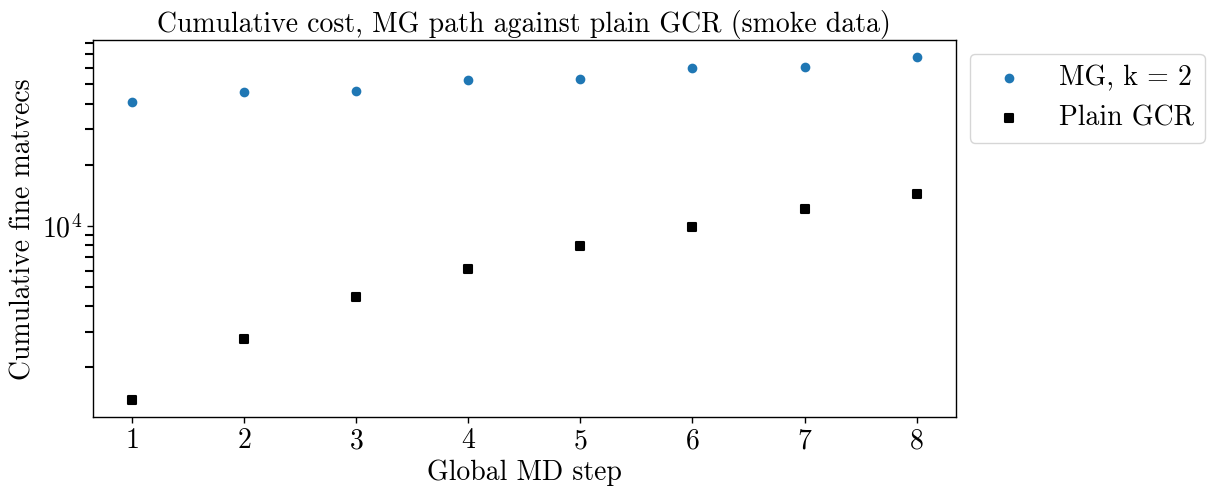

In [3]:
def cost_curve(run):
    s, u, setup = run["steps"], run["updates"], run["setup"]
    per_rebuild = setup["coarsen_matvecs"]
    per_step = s.set_index("global")["matvecs"].astype(float)
    if len(u):
        mdsteps = s["step"].max()
        u_global = (u["traj"] - 1) * mdsteps + u["step"]
        for g, mv in zip(u_global, u["matvecs"]):
            per_step.loc[g] += mv + per_rebuild
    return setup["setup_matvecs"] + per_rebuild + per_step.cumsum()

def gcr_curve(gcr, n):
    s = gcr["steps"]
    every = int(s["global"].diff().dropna().mode().iloc[0]) if len(s) > 1 else 1
    per_step = np.repeat(s["matvecs"].to_numpy() / every, every)[:n]
    return pd.Series(np.cumsum(per_step), index=np.arange(1, len(per_step) + 1))

def break_even(mg, base):
    common = mg.index.intersection(base.index)
    below = common[mg.loc[common].to_numpy() <= base.loc[common].to_numpy()]
    return int(below[0]) if len(below) else None

fig, ax = pt.add_subplots()
ax = ax[0]
labels = [r"Global MD step", r"Cumulative fine matvecs"]
for i, (label, r) in enumerate(runs.items()):
    mg = cost_curve(r)
    pt.scatter_1d(mg.index, mg.to_numpy(), ax=ax, col=pt.pal[i], mkr='o', fn_label=f"MG, {label}", ax_label=labels, logy=True)
    base = gcr_curve(gcr, len(mg))
    be = break_even(mg, base)
    print(f"{label}: MG total {mg.iloc[-1]:.0f}, baseline {base.iloc[-1]:.0f}, break-even step {be}")
pt.scatter_1d(base.index, base.to_numpy(), ax=ax, col='k', mkr='s', fn_label="Plain GCR", ax_label=labels, logy=True)
pt.add_title(ax, "Cumulative cost, MG path against plain GCR (smoke data)")
ax.legend(**LEGEND)
plt.show()

## 3. Force solves along the trajectory

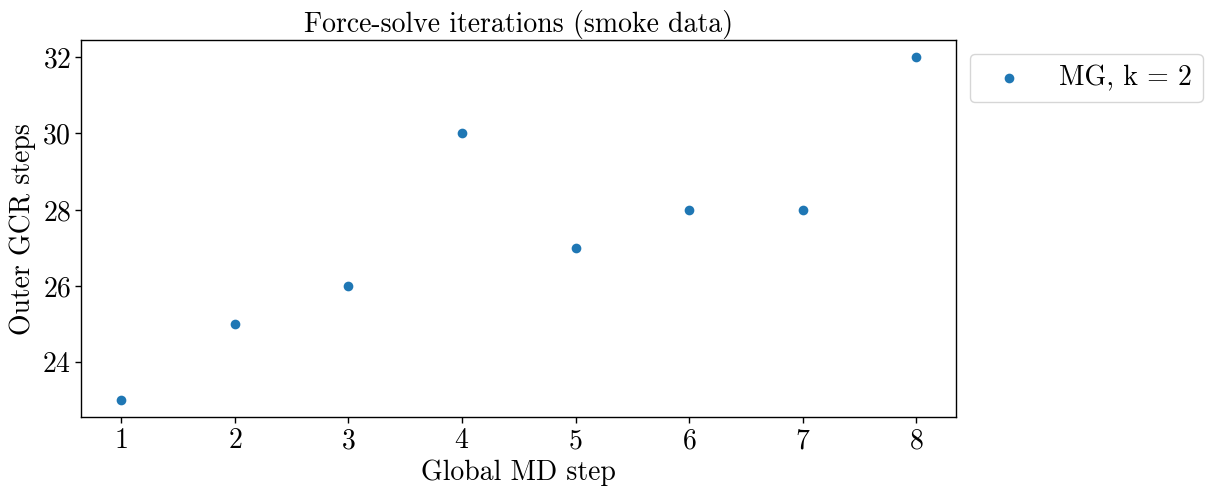

global        dU   dU_last  iters  matvecs   seconds        relres
k = 2 0       1  0.000848  0.000848     23      456  2.206460  8.950501e-09
      1       2  0.003365  0.003365     25      496  2.167878  6.474573e-09
      2       3  0.007475  0.000813     26      512  2.236550  6.172672e-09
      3       4  0.013057  0.003185     30      595  2.769114  8.988486e-09
      4       5  0.013818  0.000805     27      533  2.465183  7.305174e-09
      5       6  0.015975  0.003197     28      556  2.675728  7.829380e-09
      6       7  0.019470  0.000778     28      556  2.522479  7.869658e-09
      7       8  0.024212  0.003057     32      636  3.118974  9.899761e-09

In [4]:
fig, ax = pt.add_subplots()
ax = ax[0]
for i, (label, r) in enumerate(runs.items()):
    s = r["steps"]
    pt.scatter_1d(s["global"], s["iters"], ax=ax, col=pt.pal[i], mkr='o', fn_label=f"MG, {label}",
                  ax_label=[r"Global MD step", r"Outer GCR steps"])
pt.add_title(ax, "Force-solve iterations (smoke data)")
ax.legend(**LEGEND)
plt.show()
pd.concat({label: r["steps"][["global", "dU", "dU_last", "iters", "matvecs", "seconds", "relres"]] for label, r in runs.items()})

## 4. The updates

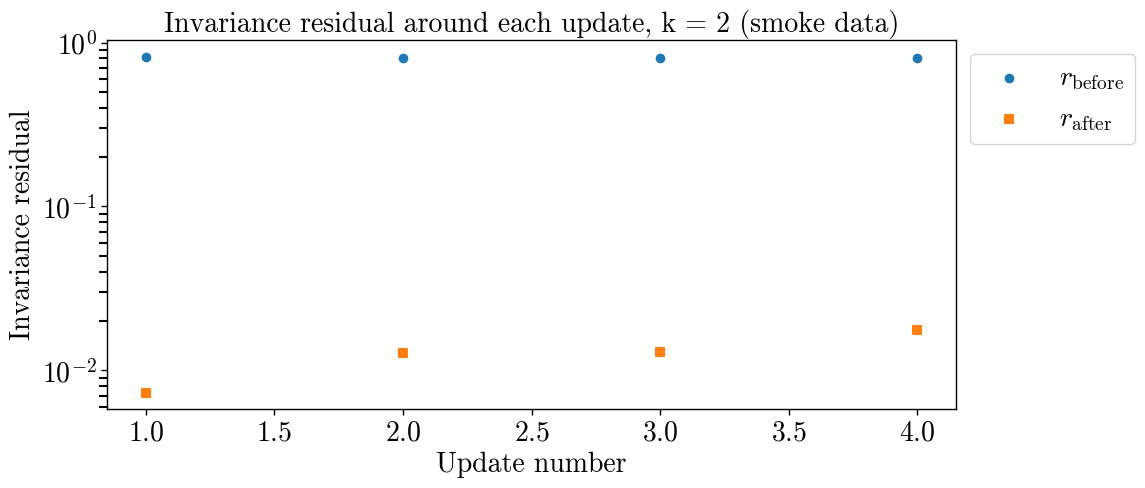

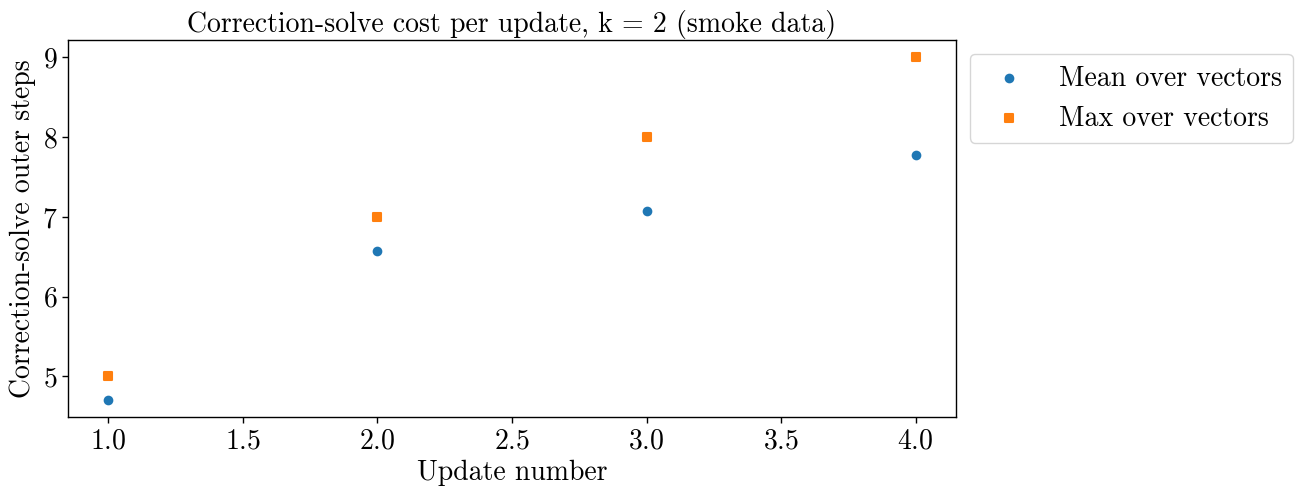

,traj,step,matvecs,seconds,capped,resid_before,resid_after,cap_S0,dist2_prev,gram_cond,iters_mean,wratio_mean
0,1,2,3920.0,22.071028,0.0,0.818428,0.007320,0.998075,0.245169,32901.4179,4.700,0.046829
1,1,4,5420.0,33.699447,0.0,0.810411,0.012689,0.991659,0.539426,31151.1085,6.575,0.051867
2,2,2,5821.0,35.901077,0.0,0.805713,0.012951,0.989273,0.205162,31004.0411,7.075,0.046982
3,2,4,6380.0,37.988538,0.0,0.800914,0.017647,0.982247,0.264183,30781.2932,7.775,0.050384


,traj,step,cap_cur,cap_S0_fresh
0,1,4,0.996715,0.984259
1,2,4,0.993170,0.961727


In [5]:
for label, r in runs.items():
    u = r["updates"].copy()
    u["n"] = np.arange(1, len(u) + 1)
    u["iters_mean"] = u["iters"].apply(np.mean)
    u["iters_max"] = u["iters"].apply(np.max)
    u["wratio_mean"] = u["wratio"].apply(np.mean)

    fig, ax = pt.add_subplots()
    ax = ax[0]
    lab = [r"Update number", r"Invariance residual"]
    pt.scatter_1d(u["n"], u["resid_before"], ax=ax, col=pt.pal[0], mkr='o', fn_label=r"$r_{\rm before}$", ax_label=lab, logy=True)
    pt.scatter_1d(u["n"], u["resid_after"], ax=ax, col=pt.pal[1], mkr='s', fn_label=r"$r_{\rm after}$", ax_label=lab, logy=True)
    pt.add_title(ax, f"Invariance residual around each update, {label} (smoke data)")
    ax.legend(**LEGEND)
    plt.show()

    fig, ax = pt.add_subplots()
    ax = ax[0]
    pt.scatter_1d(u["n"], u["iters_mean"], ax=ax, col=pt.pal[0], mkr='o', fn_label="Mean over vectors",
                  ax_label=[r"Update number", r"Correction-solve outer steps"])
    pt.scatter_1d(u["n"], u["iters_max"], ax=ax, col=pt.pal[1], mkr='s', fn_label="Max over vectors",
                  ax_label=[r"Update number", r"Correction-solve outer steps"])
    pt.add_title(ax, f"Correction-solve cost per update, {label} (smoke data)")
    ax.legend(**LEGEND)
    plt.show()

    display(u[["traj", "step", "matvecs", "seconds", "capped", "resid_before", "resid_after", "cap_S0", "dist2_prev", "gram_cond", "iters_mean", "wratio_mean"]])
    display(r["fresh"])

## 5. Conclusions

None yet: the data above are smoke runs on a $4^4$ tepid field. This section is written once the SDCC runs on `ckpoint_lat.4000` are in.